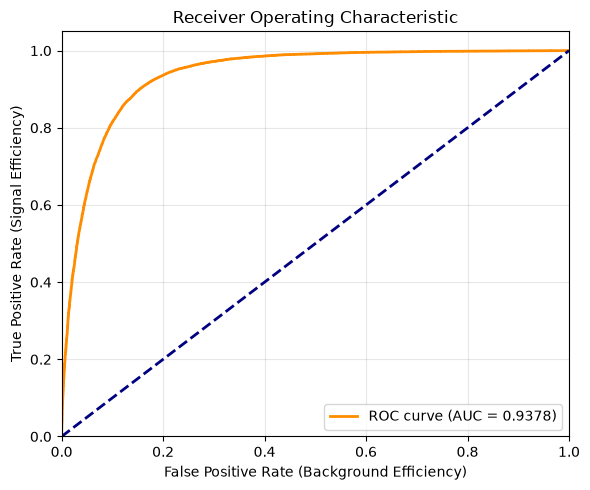

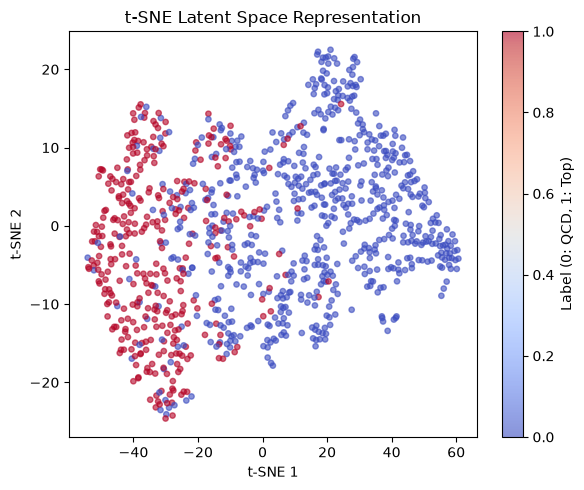

In [3]:
import torch
from jet_tagging.datamodules.jetnet_datamodule import JetDataModule
from jet_tagging.models import EncDec
from jet_tagging.modules.joint_ae_module import JointAutoencoderModule
from jet_tagging.utils.visualization import plot_roc_curve, plot_latent_space_tsne

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

checkpoint_path = "../checkpoints/encdec/epoch=14-val_loss=0.0000.ckpt" 
model = EncDec(input_size=90, latent_dim=16, output_size=2)
system = JointAutoencoderModule.load_from_checkpoint(checkpoint_path, model=model)
system.to(device)
system.eval()

dm = JetDataModule(data_mode="particle", data_dir="../data", batch_size=256)
dm.setup(stage="test")
test_loader = dm.test_dataloader()

all_probs, all_targets, all_latents = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        
        reconstructed, logits = system(x)
        latent = system.model.encoder(x)
        
        probs = torch.softmax(logits, dim=-1)[:, 1].cpu()
        
        all_probs.append(probs)
        all_targets.append(y)  # y is already on CPU
        all_latents.append(latent.cpu())

probs_np = torch.cat(all_probs).numpy()
targets_np = torch.cat(all_targets).numpy()
latents_np = torch.cat(all_latents).numpy()

fig_roc = plot_roc_curve(targets_np, probs_np)
fig_tsne = plot_latent_space_tsne(latents_np[:1000], targets_np[:1000])